# 🔥 Kalimantan FireWatch
## Spatio-Temporal Analysis & 7-Day Hotspot Prediction

Notebook ini mengerjakan seluruh pipeline **kecuali dashboard interaktif**:

- NASA FIRMS VIIRS acquisition & cleaning
- geoBoundaries ADM1/ADM2
- grid ~0.1° × 0.1°
- `grid_id × week` master table
- ERA5-Land weather features
- peatland percentage per grid
- optional MapBiomas land cover & burned-area validation
- historical + environmental EDA
- leakage-safe feature engineering
- `fire_next_7d` classification
- `hotspot_count_next_7d` count prediction
- temporal validation: 2024 train → 2025 validation → 2026 test
- Logistic Regression / Random Forest / XGBoost / LightGBM
- Poisson / Negative Binomial / XGBoost-Poisson / LightGBM-Poisson
- PR-AUC, ROC-AUC, recall, F1, MAE, RMSE, Poisson deviance
- feature importance / SHAP
- monitoring priority from probability × expected count
- export model artifacts & dashboard-ready tables

> Satu baris FIRMS diperlakukan sebagai **hotspot / active-fire detection**, bukan otomatis satu independent wildfire event.

## 0. Data sources & credentials

### Main sources
- NASA FIRMS Area API: https://firms.modaps.eosdis.nasa.gov/api/area/
- geoBoundaries API: https://www.geoboundaries.org/api.html
- ERA5-Land: https://cds.climate.copernicus.eu/datasets/reanalysis-era5-land
- Global Forest Watch / WRI — Indonesia Peat Lands: https://data.globalforestwatch.org/datasets/indonesia-peat-lands
- MapBiomas Indonesia: https://landy.mapbiomas.id/
- MapBiomas Fire: https://fire.mapbiomas.id/

### Credentials
- Set `FIRMS_MAP_KEY` sebagai environment variable.
- Konfigurasi `cdsapi` untuk Copernicus bila ingin download ERA5-Land langsung dari notebook.

### Default period
2024-01-01 sampai 2026-07-31. Ubah di konfigurasi bila perlu.

## 1. Install dependencies

In [1]:
# Google Colab / fresh environment:
!pip -q install geopandas pyogrio rtree shapely rasterio rasterstats xarray netCDF4 cdsapi scikit-learn xgboost lightgbm shap statsmodels joblib pyarrow requests tqdm matplotlib

print('Uncomment pip install if needed.')

ERROR: Could not install packages due to an OSError: [Errno 13] Permission denied: 'WHEEL'
Consider using the `--user` option or check the permissions.

Uncomment pip install if needed.


## 2. Imports

In [2]:
from __future__ import annotations

import os, io, math, time, warnings, requests
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests
from tqdm.auto import tqdm

from shapely.geometry import box
from shapely.ops import unary_union

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, PoissonRegressor
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, precision_score,
    recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay,
    precision_recall_curve, mean_absolute_error, mean_squared_error,
    mean_poisson_deviance,
)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance

import joblib
warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 120)

/home/nafisnaufal1426/miniforge3/envs/soilcpu/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 3. Configuration

In [3]:
PROJECT_DIR = Path.cwd() / 'kalimantan_firewatch'
RAW_DIR = PROJECT_DIR / 'data' / 'raw'
INTERIM_DIR = PROJECT_DIR / 'data' / 'interim'
PROCESSED_DIR = PROJECT_DIR / 'data' / 'processed'
MODEL_DIR = PROJECT_DIR / 'models'
FIG_DIR = PROJECT_DIR / 'figures'
for p in [RAW_DIR, INTERIM_DIR, PROCESSED_DIR, MODEL_DIR, FIG_DIR]:
    p.mkdir(parents=True, exist_ok=True)

START_DATE = pd.Timestamp('2024-01-01')
END_DATE = pd.Timestamp('2026-07-31')
GRID_SIZE_DEG = 0.1
WEEK_FREQ = 'W-SUN'
KALIMANTAN_BBOX = (108.0, -5.0, 119.5, 8.0)  # west, south, east, north

FIRMS_MAP_KEY = "5bf52510a62adb4b132e6cb0913ef856"
FIRMS_SOURCES = ['VIIRS_NOAA20_SP']
DOWNLOAD_FIRMS = True
DOWNLOAD_ERA5 = False

USE_PEATLAND = True
USE_LANDCOVER = False
USE_BURNED_AREA_VALIDATION = False

PEATLAND_PATH = RAW_DIR / 'peatland' / 'indonesia_peat_lands.geojson'
LANDCOVER_TIF = RAW_DIR / 'mapbiomas' / 'indonesia_coverage_2023.tif'
BURNED_AREA_TIF = RAW_DIR / 'mapbiomas_fire' / 'burned_area_2024.tif'

MODEL_SELECTION_TRAIN_END = pd.Timestamp('2024-12-31')
MODEL_SELECTION_VAL_END = pd.Timestamp('2025-12-31')
RANDOM_STATE = 42

print('Project:', PROJECT_DIR.resolve())
print('Period:', START_DATE.date(), '→', END_DATE.date())

Project: /home/nafisnaufal1426/adit/compfest_academy_2/kalimantan_firewatch
Period: 2024-01-01 → 2026-07-31


## 4. Utilities

In [4]:
WGS84 = 'EPSG:4326'
EQUAL_AREA_CRS = 'EPSG:6933'

def safe_save_gdf(gdf, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.suffix.lower() in ['.geojson', '.json']:
        gdf.to_file(path, driver='GeoJSON')
    else:
        gdf.to_file(path)
    return path

def km2_area(gdf):
    return gdf.to_crs(EQUAL_AREA_CRS).geometry.area / 1e6

def week_end_sunday(series):
    s = pd.to_datetime(series)
    return s.dt.to_period('W-SUN').dt.end_time.dt.normalize()

def report_missing(df, top=30):
    return (df.isna().mean().mul(100).sort_values(ascending=False)
            .rename('missing_pct').to_frame().head(top))

## 5. Administrative boundaries — geoBoundaries

In [5]:
def download_geoboundary(iso3='IDN', adm='ADM1', release='gbOpen'):
    url = f'https://www.geoboundaries.org/api/current/{release}/{iso3}/{adm}/'
    r = requests.get(url, timeout=60)
    r.raise_for_status()
    meta = r.json()
    return gpd.read_file(meta['gjDownloadURL']).to_crs(WGS84)

adm1_path = RAW_DIR / 'boundaries' / 'idn_adm1.geojson'
adm2_path = RAW_DIR / 'boundaries' / 'idn_adm2.geojson'

adm1 = gpd.read_file(adm1_path) if adm1_path.exists() else download_geoboundary(adm='ADM1')
adm2 = gpd.read_file(adm2_path) if adm2_path.exists() else download_geoboundary(adm='ADM2')

if not adm1_path.exists(): safe_save_gdf(adm1, adm1_path)
if not adm2_path.exists(): safe_save_gdf(adm2, adm2_path)

print('ADM1', adm1.shape, 'ADM2', adm2.shape)
display(adm1.head(3))

ADM1 (34, 6) ADM2 (519, 6)


,shapeName,shapeISO,shapeID,shapeGroup,shapeType,geometry
0,Bali,ID-BA,65028918B6690755070061,IDN,ADM1,"MULTIPOLYGON (((114.5197 -8.1, 114.52014 -8.09..."
1,West Nusa Tenggara,ID-NB,65028918B98829509874887,IDN,ADM1,"MULTIPOLYGON (((119.23765 -8.66347, 119.23757 ..."
2,Banten,ID-BT,65028918B99918739720671,IDN,ADM1,"MULTIPOLYGON (((105.53122 -7.03135, 105.5305 -..."


## 6. Extract Indonesian Kalimantan

In [6]:
name_col1 = 'shapeName' if 'shapeName' in adm1.columns else adm1.columns[0]
name_col2 = 'shapeName' if 'shapeName' in adm2.columns else adm2.columns[0]

kal_adm1 = adm1[adm1[name_col1].astype(str).str.contains('Kalimantan', case=False, na=False)].copy()
if kal_adm1.empty:
    raise ValueError("No ADM1 name containing 'Kalimantan' found.")
kal_adm1['province'] = kal_adm1[name_col1].astype(str)
kal_union = kal_adm1.geometry.union_all() if hasattr(kal_adm1.geometry, 'union_all') else unary_union(kal_adm1.geometry)

kal_adm2 = adm2[adm2.geometry.intersects(kal_union)].copy()
kal_adm2 = gpd.clip(kal_adm2, gpd.GeoDataFrame(geometry=[kal_union], crs=WGS84))
kal_adm2['district'] = kal_adm2[name_col2].astype(str)

cent = kal_adm2.to_crs(EQUAL_AREA_CRS).copy()
cent.geometry = cent.centroid
cent = cent.to_crs(WGS84)
cent = gpd.sjoin(cent[['district','geometry']], kal_adm1[['province','geometry']], how='left', predicate='within')
cent = cent.drop(columns=['index_right'], errors='ignore')
kal_adm2 = kal_adm2.merge(cent[['district','province']].drop_duplicates(), on='district', how='left')
kal_adm2['district_area_km2'] = km2_area(kal_adm2)

safe_save_gdf(kal_adm1, INTERIM_DIR / 'kalimantan_adm1.geojson')
safe_save_gdf(kal_adm2, INTERIM_DIR / 'kalimantan_adm2.geojson')
print(sorted(kal_adm1['province'].unique()))

['Central Kalimantan', 'East Kalimantan', 'North Kalimantan', 'South Kalimantan', 'West Kalimantan']


## 7. NASA FIRMS acquisition

In [7]:
def daterange_chunks(start, end, max_days=5):
    cur = pd.Timestamp(start).normalize()
    end = pd.Timestamp(end).normalize()
    while cur <= end:
        n = min(max_days, (end-cur).days + 1)
        yield cur, n
        cur += pd.Timedelta(days=n)

def download_firms_area(map_key, source, bbox, start, end, sleep_seconds=0.15):
    if not map_key:
        raise ValueError('FIRMS_MAP_KEY is empty.')
    west, south, east, north = bbox
    area = f'{west},{south},{east},{north}'
    frames=[]
    chunks=list(daterange_chunks(start,end,5))
    for d0, n in tqdm(chunks, desc=f'FIRMS {source}'):
        url = ('https://firms.modaps.eosdis.nasa.gov/api/area/csv/'
               f'{map_key}/{source}/{area}/{n}/{d0:%Y-%m-%d}')
        try:
            r=requests.get(url,timeout=90); r.raise_for_status()
            text=r.text.strip()
            if text and not text.lower().startswith('error'):
                z=pd.read_csv(io.StringIO(text))
                if len(z):
                    z['source_product']=source
                    frames.append(z)
        except Exception as e:
            print('Warning', d0.date(), source, repr(e))
        time.sleep(sleep_seconds)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()

firms_raw_path = RAW_DIR / 'firms' / f'firms_{START_DATE:%Y%m%d}_{END_DATE:%Y%m%d}.parquet'
firms_raw_path.parent.mkdir(parents=True, exist_ok=True)

if firms_raw_path.exists():
    firms_raw=pd.read_parquet(firms_raw_path)
elif DOWNLOAD_FIRMS:
    frames=[]
    for src in FIRMS_SOURCES:
        z=download_firms_area(FIRMS_MAP_KEY, src, KALIMANTAN_BBOX, START_DATE, END_DATE)
        if len(z): frames.append(z)
    if not frames:
        raise RuntimeError('No FIRMS data downloaded. Check MAP_KEY/product/date availability.')
    firms_raw=pd.concat(frames,ignore_index=True)
    firms_raw.to_parquet(firms_raw_path,index=False)
else:
    raise FileNotFoundError(firms_raw_path)

print('Raw FIRMS rows:', len(firms_raw))
display(firms_raw.head())

FIRMS VIIRS_NOAA20_SP:  34%|███▍      | 65/189 [02:22<03:56,  1.91s/it]

Warning 2024-11-16 VIIRS_NOAA20_SP HTTPError('502 Server Error: Bad Gateway for url: https://firms.modaps.eosdis.nasa.gov/api/area/csv/5bf52510a62adb4b132e6cb0913ef856/VIIRS_NOAA20_SP/108.0,-5.0,119.5,8.0/5/2024-11-16')


FIRMS VIIRS_NOAA20_SP: 100%|██████████| 189/189 [06:19<00:00,  2.01s/it]


Raw FIRMS rows: 94193


,latitude,longitude,bright_ti4,scan,track,acq_date,acq_time,satellite,instrument,confidence,version,bright_ti5,frp,daynight,type,source_product
0,-3.26884,114.96905,340.27,0.54,0.42,2024-01-01,604,N20,VIIRS,n,2,292.15,8.77,D,0,VIIRS_NOAA20_SP
1,-3.26790,114.96995,334.52,0.54,0.42,2024-01-01,604,N20,VIIRS,n,2,291.63,6.56,D,0,VIIRS_NOAA20_SP
2,-2.27770,116.10994,344.79,0.44,0.46,2024-01-01,605,N20,VIIRS,n,2,293.73,9.90,D,0,VIIRS_NOAA20_SP
3,-2.21259,115.49476,335.01,0.40,0.45,2024-01-01,605,N20,VIIRS,n,2,295.69,3.67,D,0,VIIRS_NOAA20_SP
4,-2.16103,115.58388,331.45,0.41,0.45,2024-01-01,605,N20,VIIRS,n,2,291.05,1.96,D,2,VIIRS_NOAA20_SP


## 8. Clean FIRMS, filter polygon, join district

In [8]:
def clean_firms(df):
    x=df.copy()
    if 'bright_ti4' in x.columns and 'brightness' not in x.columns:
        x['brightness']=x['bright_ti4']
    for c in ['latitude','longitude','frp']:
        if c in x.columns: x[c]=pd.to_numeric(x[c],errors='coerce')
    x['acq_date']=pd.to_datetime(x['acq_date'],errors='coerce')
    x=x.dropna(subset=['latitude','longitude','acq_date'])
    x=x[x['latitude'].between(-90,90)&x['longitude'].between(-180,180)].copy()
    if 'confidence' in x.columns:
        x['confidence']=x['confidence'].astype(str).str.lower().str.strip()
        x['high_confidence']=x['confidence'].isin(['h','high']).astype(int)
    else:
        x['confidence']='unknown'; x['high_confidence']=0
    keys=[c for c in ['latitude','longitude','acq_date','acq_time','satellite','source_product'] if c in x.columns]
    return x.drop_duplicates(keys).reset_index(drop=True)

firms_clean=clean_firms(firms_raw)
firms_gdf=gpd.GeoDataFrame(firms_clean, geometry=gpd.points_from_xy(firms_clean.longitude,firms_clean.latitude),crs=WGS84)
firms_kal=firms_gdf[firms_gdf.geometry.intersects(kal_union)].copy()

firms_admin=gpd.sjoin(
    firms_kal,
    kal_adm2[['district','province','district_area_km2','geometry']],
    how='left',predicate='within'
).drop(columns=['index_right'],errors='ignore')

print('Inside Indonesian Kalimantan:',len(firms_admin))
print('District unmatched:',firms_admin['district'].isna().mean())
display(report_missing(firms_admin))
firms_admin.drop(columns='geometry').to_parquet(INTERIM_DIR/'firms_kalimantan_clean.parquet',index=False)

Inside Indonesian Kalimantan: 75702
District unmatched: 0.0006208554595651369


,missing_pct
district,0.062086
district_area_km2,0.062086
province,0.062086
bright_ti4,0.000000
latitude,0.000000
longitude,0.000000
acq_date,0.000000
track,0.000000
scan,0.000000
acq_time,0.000000


## 9. Historical EDA

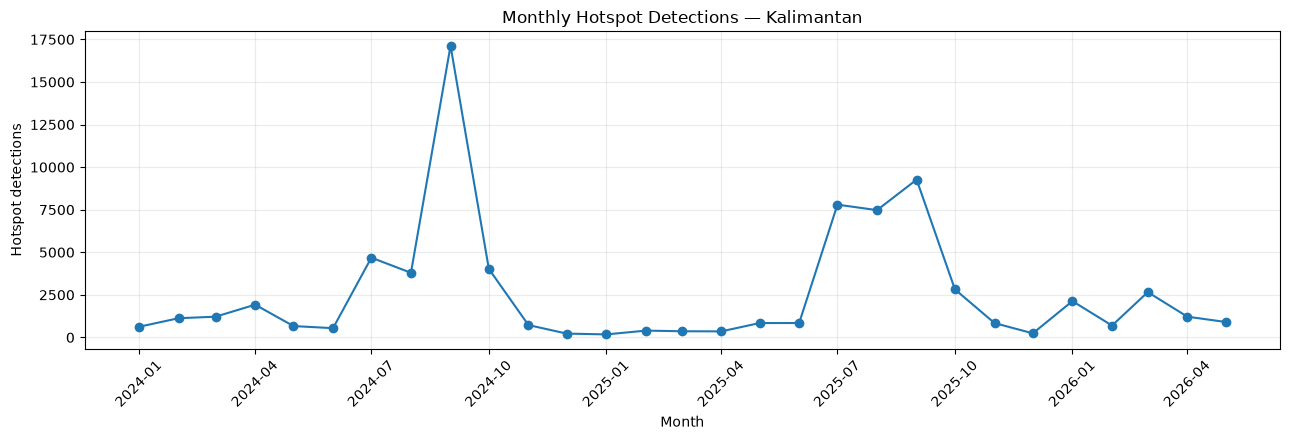

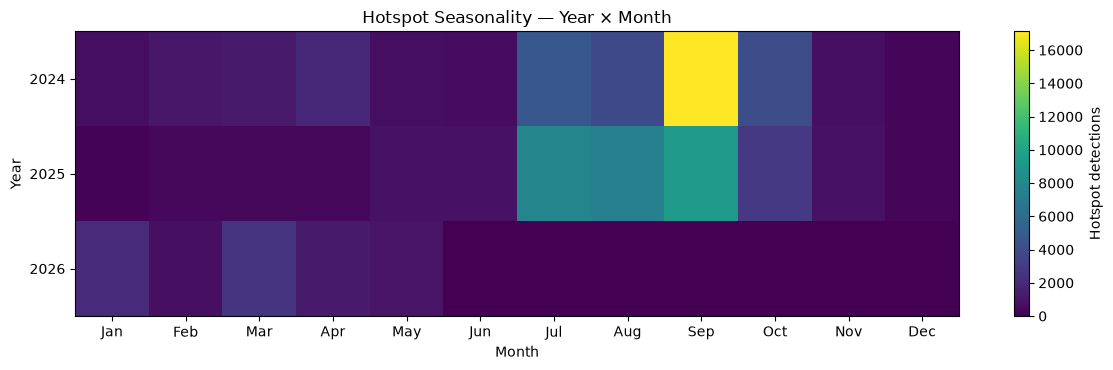

In [9]:
monthly=(firms_admin.assign(month=firms_admin['acq_date'].dt.to_period('M').dt.to_timestamp())
         .groupby('month').agg(hotspot_count=('latitude','size'),avg_frp=('frp','mean'),
                               high_confidence_rate=('high_confidence','mean')).reset_index())
fig,ax=plt.subplots(figsize=(13,4.5)); ax.plot(monthly['month'],monthly['hotspot_count'],marker='o')
ax.set(title='Monthly Hotspot Detections — Kalimantan',xlabel='Month',ylabel='Hotspot detections'); ax.grid(alpha=.25)
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

season=(firms_admin.assign(year=firms_admin['acq_date'].dt.year,month=firms_admin['acq_date'].dt.month)
        .groupby(['year','month']).size().unstack(fill_value=0).reindex(columns=range(1,13),fill_value=0))
fig,ax=plt.subplots(figsize=(12,3.8)); im=ax.imshow(season.values,aspect='auto')
ax.set_yticks(range(len(season.index))); ax.set_yticklabels(season.index)
ax.set_xticks(range(12)); ax.set_xticklabels(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])
ax.set(title='Hotspot Seasonality — Year × Month',xlabel='Month',ylabel='Year'); fig.colorbar(im,ax=ax,label='Hotspot detections')
plt.tight_layout(); plt.show()

## 10. District hotspot density

,province,district,district_area_km2,hotspot_count,hotspots_per_1000_km2
48,East Kalimantan,Kota Bontang,163.240635,201.0,1231.311065
41,West Kalimantan,Mempawah,1995.842896,1992.0,998.074550
42,West Kalimantan,Sanggau,12754.069675,7908.0,620.037384
34,South Kalimantan,Tabalong,3159.345885,1926.0,609.619861
39,West Kalimantan,Sekadau,5700.997319,3241.0,568.497022
15,South Kalimantan,Tapin,2191.433369,1007.0,459.516595
43,West Kalimantan,Landak,8252.761741,3785.0,458.634348
16,South Kalimantan,Hulu Sungai Selatan,1697.039958,743.0,437.821158
46,West Kalimantan,Bengkayang,5619.893697,2265.0,403.032534
47,West Kalimantan,Sambas,5777.485433,1946.0,336.824735


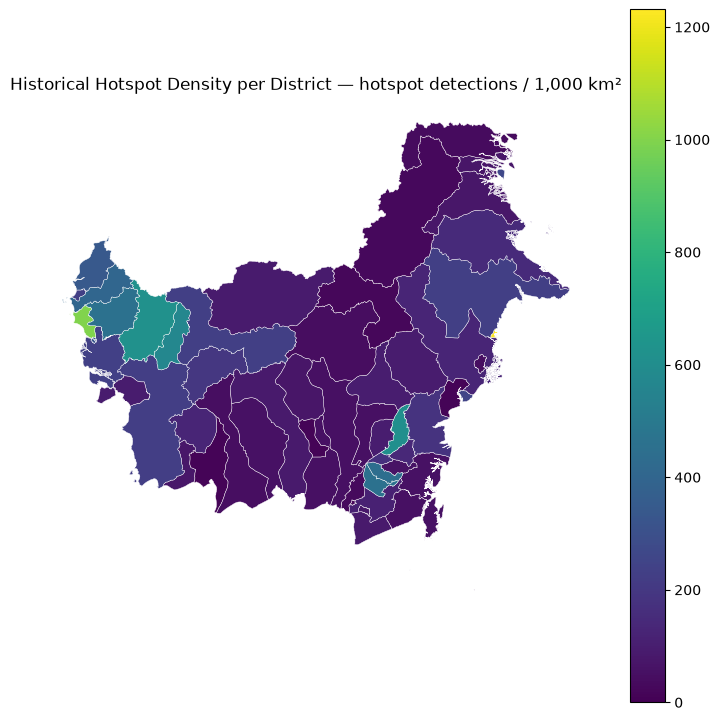

In [10]:
district_hotspots=firms_admin.groupby(['province','district'],dropna=False).size().rename('hotspot_count').reset_index()
district_stats=kal_adm2[['province','district','district_area_km2','geometry']].merge(district_hotspots,on=['province','district'],how='left')
district_stats['hotspot_count']=district_stats['hotspot_count'].fillna(0)
district_stats['hotspots_per_1000_km2']=district_stats['hotspot_count']/district_stats['district_area_km2']*1000
display(district_stats.drop(columns='geometry').sort_values('hotspots_per_1000_km2',ascending=False).head(15))
ax=district_stats.plot(column='hotspots_per_1000_km2',figsize=(9,9),legend=True,edgecolor='white',linewidth=.3)
ax.set_title('Historical Hotspot Density per District — hotspot detections / 1,000 km²'); ax.set_axis_off(); plt.show()

## 11. Build 0.1° spatial grid

In [11]:
def build_regular_grid(mask_geom,grid_size=.1):
    minx,miny,maxx,maxy=mask_geom.bounds
    x0=math.floor(minx/grid_size)*grid_size; y0=math.floor(miny/grid_size)*grid_size
    x1=math.ceil(maxx/grid_size)*grid_size; y1=math.ceil(maxy/grid_size)*grid_size
    rec=[]
    for r,y in enumerate(np.arange(y0,y1,grid_size)):
        for c,x in enumerate(np.arange(x0,x1,grid_size)):
            geom=box(x,y,x+grid_size,y+grid_size)
            if geom.intersects(mask_geom):
                rec.append({'grid_row':r,'grid_col':c,'geometry':geom.intersection(mask_geom)})
    g=gpd.GeoDataFrame(rec,crs=WGS84).reset_index(drop=True)
    g['grid_id']=[f'G{i:05d}' for i in range(1,len(g)+1)]
    return g

grid=build_regular_grid(kal_union,GRID_SIZE_DEG)
grid['grid_area_km2']=km2_area(grid)
rep=grid.to_crs(EQUAL_AREA_CRS).copy(); rep.geometry=rep.representative_point(); rep=rep.to_crs(WGS84)
grid['centroid_lon']=rep.geometry.x.values; grid['centroid_lat']=rep.geometry.y.values
admin=gpd.sjoin(rep[['grid_id','geometry']],kal_adm2[['district','province','geometry']],how='left',predicate='within').drop(columns=['index_right'],errors='ignore')
grid=grid.merge(admin[['grid_id','district','province']].drop_duplicates('grid_id'),on='grid_id',how='left')
safe_save_gdf(grid,PROCESSED_DIR/'dim_grid.geojson')
print('Grid cells:',len(grid)); display(grid.head())

Grid cells: 4672


,grid_row,grid_col,geometry,grid_id,grid_area_km2,centroid_lon,centroid_lat,district,province
0,0,85,"POLYGON ((117.05964 -5.1, 117.05943 -5.10023, ...",G00001,0.112900,117.056030,-5.101136,Pangkajene Dan Kepulauan,South Kalimantan
1,1,85,"POLYGON ((117.05185 -5.1, 117.05185 -5.09972, ...",G00002,1.400701,117.050756,-5.094176,Pangkajene Dan Kepulauan,South Kalimantan
2,2,71,"POLYGON ((115.67608 -4.9, 115.67605 -4.90036, ...",G00003,6.037779,115.656297,-4.919541,NaN,NaN
3,3,71,"POLYGON ((115.66952 -4.9, 115.66933 -4.89919, ...",G00004,0.498741,115.675229,-4.895866,NaN,NaN
4,3,72,"POLYGON ((115.8 -4.8, 115.8 -4.82526, 115.7975...",G00005,6.903346,115.790145,-4.818594,NaN,NaN


## 12. Assign FIRMS to grid & complete grid-week frame

In [12]:
firms_grid=gpd.sjoin(
    firms_admin.drop(columns=['district','province','district_area_km2'],errors='ignore'),
    grid[['grid_id','province','district','grid_area_km2','geometry']],how='inner',predicate='within'
).drop(columns=['index_right'],errors='ignore')
firms_grid['week']=week_end_sunday(firms_grid['acq_date'])

all_weeks=pd.date_range(START_DATE.to_period('W-SUN').end_time.normalize(),END_DATE.to_period('W-SUN').end_time.normalize(),freq=WEEK_FREQ)
base=pd.MultiIndex.from_product([grid['grid_id'],all_weeks],names=['grid_id','week']).to_frame(index=False)
fire_weekly=(firms_grid.groupby(['grid_id','week']).agg(hotspot_count=('latitude','size'),avg_frp=('frp','mean'),
              max_frp=('frp','max'),high_confidence_rate=('high_confidence','mean')).reset_index())
base=base.merge(fire_weekly,on=['grid_id','week'],how='left')
base['hotspot_count']=base['hotspot_count'].fillna(0).astype(int)
base['high_confidence_rate']=base['high_confidence_rate'].fillna(0.)
base=base.merge(grid.drop(columns='geometry')[['grid_id','centroid_lat','centroid_lon','grid_area_km2','province','district']],on='grid_id',how='left')
print('Complete grid-week rows:',len(base))

Complete grid-week rows: 630720


## 13. Exact fire-history rolling features

In [13]:
def build_daily_fire_features(firms_grid,grid_ids,start_date,end_date):
    daily_dates=pd.date_range(start_date,end_date,freq='D')
    daily=pd.MultiIndex.from_product([grid_ids,daily_dates],names=['grid_id','date']).to_frame(index=False)
    d=firms_grid.copy(); d['date']=pd.to_datetime(d['acq_date']).dt.normalize()
    agg=(d.groupby(['grid_id','date']).agg(daily_hotspots=('latitude','size'),daily_frp_sum=('frp','sum'),daily_frp_n=('frp','count')).reset_index())
    daily=daily.merge(agg,on=['grid_id','date'],how='left')
    daily[['daily_hotspots','daily_frp_sum','daily_frp_n']]=daily[['daily_hotspots','daily_frp_sum','daily_frp_n']].fillna(0)
    daily=daily.sort_values(['grid_id','date']).reset_index(drop=True)
    g=daily.groupby('grid_id',group_keys=False)
    for w in [7,14,30]:
        daily[f'hotspot_prev_{w}d']=g['daily_hotspots'].rolling(w,min_periods=1).sum().reset_index(level=0,drop=True)
    frp_sum=g['daily_frp_sum'].rolling(30,min_periods=1).sum().reset_index(level=0,drop=True)
    frp_n=g['daily_frp_n'].rolling(30,min_periods=1).sum().reset_index(level=0,drop=True)
    daily['avg_frp_prev_30d']=frp_sum/frp_n.replace(0,np.nan)
    daily['last_hotspot_date']=daily['date'].where(daily['daily_hotspots']>0)
    daily['last_hotspot_date']=daily.groupby('grid_id')['last_hotspot_date'].ffill()
    daily['days_since_last_hotspot']=(daily['date']-daily['last_hotspot_date']).dt.days
    daily['week']=week_end_sunday(daily['date'])
    out=daily[daily['date']==daily['week']].copy()
    return out[['grid_id','week','hotspot_prev_7d','hotspot_prev_14d','hotspot_prev_30d','avg_frp_prev_30d','days_since_last_hotspot']]

fire_hist_path=INTERIM_DIR/'fire_history_features.parquet'
if fire_hist_path.exists():
    fire_history=pd.read_parquet(fire_hist_path)
else:
    fire_history=build_daily_fire_features(firms_grid,grid['grid_id'].tolist(),START_DATE,END_DATE)
    fire_history.to_parquet(fire_hist_path,index=False)
base=base.merge(fire_history,on=['grid_id','week'],how='left')
display(base[['grid_id','week','hotspot_prev_7d','hotspot_prev_30d','days_since_last_hotspot']].head())

,grid_id,week,hotspot_prev_7d,hotspot_prev_30d,days_since_last_hotspot
0,G00001,2024-01-07,0.0,0.0,NaN
1,G00001,2024-01-14,0.0,0.0,NaN
2,G00001,2024-01-21,0.0,0.0,NaN
3,G00001,2024-01-28,0.0,0.0,NaN
4,G00001,2024-02-04,0.0,0.0,NaN


## 14. Peatland load & `peat_pct`

In [14]:
PEAT_ARCGIS_QUERY=('https://gfw-staging.wri.org/arcgis/rest/services/country_data/asia/MapServer/10/query'
                   '?where=1%3D1&outFields=*&returnGeometry=true&f=geojson')

def load_peatland(path=PEATLAND_PATH):
    path=Path(path)
    if path.exists(): return gpd.read_file(path).to_crs(WGS84)
    if not USE_PEATLAND: return None
    path.parent.mkdir(parents=True,exist_ok=True)
    try:
        r=requests.get(PEAT_ARCGIS_QUERY,timeout=120); r.raise_for_status(); gj=r.json()
        peat=gpd.GeoDataFrame.from_features(gj['features'],crs=WGS84); safe_save_gdf(peat,path); return peat
    except Exception as e:
        print('Auto peat download failed:',repr(e))
        print('Download manually and save to',path)
        return None

def polygon_coverage_pct(grid_gdf,cover_gdf,out_col='peat_pct'):
    g=grid_gdf[['grid_id','geometry']].to_crs(EQUAL_AREA_CRS).copy()
    c=cover_gdf[['geometry']].to_crs(EQUAL_AREA_CRS)
    union=c.geometry.union_all() if hasattr(c.geometry,'union_all') else unary_union(c.geometry)
    a=g.geometry.area; covered=g.geometry.intersection(union).area
    g[out_col]=np.where(a>0,covered/a*100,np.nan)
    return g[['grid_id',out_col]]

peat=load_peatland()
if peat is not None:
    peat_grid=polygon_coverage_pct(grid,peat)
else:
    peat_grid=grid[['grid_id']].copy(); peat_grid['peat_pct']=np.nan
base=base.merge(peat_grid,on='grid_id',how='left')
display(base[['grid_id','peat_pct']].drop_duplicates().sort_values('peat_pct',ascending=False).head(10))

Auto peat download failed: TypeError("float() argument must be a string or a real number, not 'NoneType'")
Download manually and save to /home/nafisnaufal1426/adit/compfest_academy_2/kalimantan_firewatch/data/raw/peatland/indonesia_peat_lands.geojson


,grid_id,peat_pct
0,G00001,NaN
135,G00002,NaN
270,G00003,NaN
405,G00004,NaN
540,G00005,NaN
675,G00006,NaN
810,G00007,NaN
945,G00008,NaN
1080,G00009,NaN
1215,G00010,NaN


## 15. ERA5-Land monthly download

In [15]:
def month_starts(start,end):
    return pd.date_range(pd.Timestamp(start).replace(day=1),pd.Timestamp(end).replace(day=1),freq='MS')
def days_in_month(ts): return [f'{d:02d}' for d in range(1,ts.days_in_month+1)]

ERA5_VARS=['total_precipitation','2m_temperature','volumetric_soil_water_layer_1']
ERA5_AREA=[KALIMANTAN_BBOX[3],KALIMANTAN_BBOX[0],KALIMANTAN_BBOX[1],KALIMANTAN_BBOX[2]]
era5_dir=RAW_DIR/'era5_land'; era5_dir.mkdir(parents=True,exist_ok=True)

def download_era5_land_month(ts,target_dir=era5_dir):
    import cdsapi
    target=Path(target_dir)/f'era5_land_{ts:%Y_%m}.nc'
    if target.exists(): return target
    req={'variable':ERA5_VARS,'year':f'{ts.year}','month':f'{ts.month:02d}','day':days_in_month(ts),
         'time':[f'{h:02d}:00' for h in range(24)],'data_format':'netcdf','download_format':'unarchived','area':ERA5_AREA}
    cdsapi.Client().retrieve('reanalysis-era5-land',req,str(target))
    return target

if DOWNLOAD_ERA5:
    for ts in tqdm(month_starts(START_DATE,END_DATE),desc='ERA5 monthly'):
        try: download_era5_land_month(ts)
        except Exception as e: print('ERA5 failed',ts.strftime('%Y-%m'),repr(e))
else:
    print('DOWNLOAD_ERA5=False. Configure CDS API then enable when ready.')

era5_files=sorted(era5_dir.glob('*.nc')); print('ERA5 files:',len(era5_files))

DOWNLOAD_ERA5=False. Configure CDS API then enable when ready.
ERA5 files: 0


## 16. Process ERA5-Land → daily → rolling → grid-week

In [16]:
def _find_var(ds,candidates):
    for c in candidates:
        if c in ds.data_vars: return c
    raise KeyError((candidates,list(ds.data_vars)))

def process_era5_file(path):
    import xarray as xr
    ds=xr.open_dataset(path)
    tname='valid_time' if 'valid_time' in ds.coords else 'time'
    lat='latitude' if 'latitude' in ds.coords else 'lat'; lon='longitude' if 'longitude' in ds.coords else 'lon'
    tp=_find_var(ds,['tp','total_precipitation']); t2m=_find_var(ds,['t2m','2m_temperature']); sw=_find_var(ds,['swvl1','volumetric_soil_water_layer_1'])
    df=ds[[tp,t2m,sw]].rename({tp:'tp',t2m:'t2m',sw:'swvl1'}).to_dataframe().reset_index()
    df[tname]=pd.to_datetime(df[tname]); df['date']=df[tname].dt.normalize()
    df['rain_mm_hour']=df['tp'].astype(float)*1000; df['temperature_c']=df['t2m'].astype(float)-273.15; df['soil_moisture']=df['swvl1'].astype(float)
    out=(df.groupby([lat,lon,'date']).agg(rainfall_daily_mm=('rain_mm_hour','sum'),temperature_mean_daily=('temperature_c','mean'),
         temperature_max_daily=('temperature_c','max'),soil_moisture_daily=('soil_moisture','mean')).reset_index().rename(columns={lat:'latitude',lon:'longitude'}))
    ds.close(); return out

def build_era5_weekly_features(x):
    x=x.sort_values(['latitude','longitude','date']).copy(); g=x.groupby(['latitude','longitude'],group_keys=False)
    for w in [7,14,30]:
        x[f'rainfall_{w}d']=g['rainfall_daily_mm'].rolling(w,min_periods=1).sum().reset_index(level=[0,1],drop=True)
    x['dry_day']=(x['rainfall_daily_mm']<1.0).astype(int)
    x['dry_days_30d']=g['dry_day'].rolling(30,min_periods=1).sum().reset_index(level=[0,1],drop=True)
    x['temperature_mean_7d']=g['temperature_mean_daily'].rolling(7,min_periods=1).mean().reset_index(level=[0,1],drop=True)
    x['temperature_max_7d']=g['temperature_max_daily'].rolling(7,min_periods=1).max().reset_index(level=[0,1],drop=True)
    x['soil_moisture_7d']=g['soil_moisture_daily'].rolling(7,min_periods=1).mean().reset_index(level=[0,1],drop=True)
    x['week']=week_end_sunday(x['date']); out=x[x['date']==x['week']].copy()
    return out[['latitude','longitude','week','rainfall_7d','rainfall_14d','rainfall_30d','temperature_mean_7d','temperature_max_7d','soil_moisture_7d','dry_days_30d']]

def aggregate_era5_to_grid(points,grid_gdf):
    pts=gpd.GeoDataFrame(points.copy(),geometry=gpd.points_from_xy(points.longitude,points.latitude),crs=WGS84)
    j=gpd.sjoin(pts,grid_gdf[['grid_id','geometry']],how='inner',predicate='within').drop(columns=['index_right','geometry'],errors='ignore')
    vals=['rainfall_7d','rainfall_14d','rainfall_30d','temperature_mean_7d','temperature_max_7d','soil_moisture_7d','dry_days_30d']
    return j.groupby(['grid_id','week'])[vals].mean().reset_index()

era5_grid_cache=INTERIM_DIR/'era5_grid_week.parquet'
if era5_grid_cache.exists():
    era5_grid_week=pd.read_parquet(era5_grid_cache)
elif era5_files:
    era5_daily=pd.concat([process_era5_file(f) for f in tqdm(era5_files,desc='Process ERA5')],ignore_index=True)
    era5_daily=era5_daily[era5_daily['date'].between(START_DATE,END_DATE)].copy()
    era5_daily.to_parquet(INTERIM_DIR/'era5_daily.parquet',index=False)
    era5_grid_week=aggregate_era5_to_grid(build_era5_weekly_features(era5_daily),grid)
    era5_grid_week.to_parquet(era5_grid_cache,index=False)
else:
    era5_grid_week=pd.DataFrame(columns=['grid_id','week'])

base=base.merge(era5_grid_week,on=['grid_id','week'],how='left')
print('After ERA5 merge:',base.shape); display(report_missing(base))

After ERA5 merge: (630720, 17)


,missing_pct
peat_pct,100.000000
avg_frp,96.397926
max_frp,96.397926
avg_frp_prev_30d,89.513572
days_since_last_hotspot,53.033834
district,0.791952
province,0.791952
hotspot_prev_14d,0.740741
hotspot_prev_7d,0.740741
hotspot_prev_30d,0.740741


## 17. Optional MapBiomas land cover & burned area

In [17]:
def landcover_histogram_per_grid(grid_gdf,raster_path):
    from rasterstats import zonal_stats
    zs=zonal_stats(grid_gdf,str(raster_path),categorical=True,nodata=0,all_touched=False)
    rows=[]
    for gid,hist in zip(grid_gdf['grid_id'],zs):
        total=sum(hist.values()) or np.nan; row={'grid_id':gid}
        for cls,count in hist.items(): row[f'lc_{int(cls)}_pct']=count/total*100
        row['dominant_landcover_code']=int(max(hist.items(),key=lambda z:z[1])[0]) if hist else np.nan
        rows.append(row)
    return pd.DataFrame(rows)

def sample_raster_at_points(points_gdf,raster_path,out_col='value'):
    import rasterio
    pts=points_gdf.copy()
    with rasterio.open(raster_path) as src:
        if src.crs: pts=pts.to_crs(src.crs)
        vals=[v[0] for v in src.sample([(g.x,g.y) for g in pts.geometry])]
    out=points_gdf.copy(); out[out_col]=vals; return out

if USE_LANDCOVER and LANDCOVER_TIF.exists():
    base=base.merge(landcover_histogram_per_grid(grid,LANDCOVER_TIF),on='grid_id',how='left')
else: print('Land cover skipped.')

if USE_BURNED_AREA_VALIDATION and BURNED_AREA_TIF.exists():
    fb=sample_raster_at_points(firms_grid,BURNED_AREA_TIF,'burned_area_value')
    fb['burned_area_match']=pd.to_numeric(fb['burned_area_value'],errors='coerce').fillna(0)>0
    print('Burned-area match:',fb['burned_area_match'].mean())
else: print('Burned-area validation skipped.')

Land cover skipped.
Burned-area validation skipped.


## 18. Environmental EDA

In [18]:
if 'rainfall_30d' in base and base['rainfall_30d'].notna().any():
    s=base.dropna(subset=['rainfall_30d']); s=s.sample(min(len(s),60000),random_state=RANDOM_STATE)
    fig,ax=plt.subplots(figsize=(7,5)); ax.scatter(s['rainfall_30d'],s['hotspot_count'],alpha=.18,s=12)
    ax.set(title='Rainfall 30D vs Weekly Hotspot Activity',xlabel='Rainfall previous 30d (mm)',ylabel='Weekly hotspot detections'); ax.grid(alpha=.2); plt.show()
    print('Spearman association:',base[['rainfall_30d','hotspot_count']].corr(method='spearman').iloc[0,1])

if 'soil_moisture_7d' in base and base['soil_moisture_7d'].notna().any():
    s=base.dropna(subset=['soil_moisture_7d']); s=s.sample(min(len(s),60000),random_state=RANDOM_STATE)
    fig,ax=plt.subplots(figsize=(7,5)); ax.scatter(s['soil_moisture_7d'],s['hotspot_count'],alpha=.18,s=12)
    ax.set(title='Soil Moisture vs Weekly Hotspot Activity',xlabel='Soil moisture 7d mean',ylabel='Weekly hotspot detections'); ax.grid(alpha=.2); plt.show()

if 'peat_pct' in base and base['peat_pct'].notna().any():
    p=base.copy(); p['peat_group']=np.where(p['peat_pct']>0,'Peat','Non-Peat'); p['hotspot_density_week']=p['hotspot_count']/p['grid_area_km2']*1000
    summ=p.groupby('peat_group').agg(hotspot_density=('hotspot_density_week','mean'),avg_frp=('avg_frp','mean'),high_confidence_rate=('high_confidence_rate','mean'))
    display(summ)
    summ.plot(kind='bar',figsize=(8,5),title='Peat vs Non-Peat'); plt.xticks(rotation=0); plt.tight_layout(); plt.show()

## 19. Targets & leakage-safe feature list

In [19]:
model_df=base.sort_values(['grid_id','week']).reset_index(drop=True).copy()
model_df['month']=model_df['week'].dt.month
model_df['week_of_year']=model_df['week'].dt.isocalendar().week.astype(int)
model_df['dry_season']=model_df['month'].isin([5,6,7,8,9,10]).astype(int)
model_df['hotspot_count_next_7d']=model_df.groupby('grid_id')['hotspot_count'].shift(-1)
model_df['fire_next_7d']=model_df['hotspot_count_next_7d'].gt(0).astype('Int64')
model_df=model_df[model_df['hotspot_count_next_7d'].notna()].copy()
model_df['hotspot_count_next_7d']=model_df['hotspot_count_next_7d'].astype(int); model_df['fire_next_7d']=model_df['fire_next_7d'].astype(int)

CANDIDATE_FEATURES=['hotspot_prev_7d','hotspot_prev_14d','hotspot_prev_30d','avg_frp_prev_30d','days_since_last_hotspot',
                    'rainfall_7d','rainfall_14d','rainfall_30d','temperature_mean_7d','temperature_max_7d','soil_moisture_7d','dry_days_30d',
                    'peat_pct','month','week_of_year','dry_season']
FEATURES=[c for c in CANDIDATE_FEATURES if c in model_df.columns]
assert 'fire_next_7d' not in FEATURES and 'hotspot_count_next_7d' not in FEATURES
print('Rows:',len(model_df),'positive rate:',model_df['fire_next_7d'].mean()); print(FEATURES)
display(report_missing(model_df[FEATURES]))

Rows: 626048 positive rate: 0.036212878245757515
['hotspot_prev_7d', 'hotspot_prev_14d', 'hotspot_prev_30d', 'avg_frp_prev_30d', 'days_since_last_hotspot', 'peat_pct', 'month', 'week_of_year', 'dry_season']


,missing_pct
peat_pct,100.000000
avg_frp_prev_30d,89.435315
days_since_last_hotspot,52.683341
hotspot_prev_7d,0.000000
hotspot_prev_30d,0.000000
hotspot_prev_14d,0.000000
month,0.000000
week_of_year,0.000000
dry_season,0.000000


## 20. Temporal split

In [20]:
train_sel=model_df[model_df['week']<=MODEL_SELECTION_TRAIN_END].copy()
val_sel=model_df[(model_df['week']>MODEL_SELECTION_TRAIN_END)&(model_df['week']<=MODEL_SELECTION_VAL_END)].copy()
test_final=model_df[model_df['week']>MODEL_SELECTION_VAL_END].copy()
print('2024 train',len(train_sel),train_sel['week'].min(),train_sel['week'].max())
print('2025 validation',len(val_sel),val_sel['week'].min(),val_sel['week'].max())
print('2026 test',len(test_final),test_final['week'].min(),test_final['week'].max())
assert train_sel['week'].max()<val_sel['week'].min()<test_final['week'].min()

2024 train 242944 2024-01-07 00:00:00 2024-12-29 00:00:00
2025 validation 242944 2025-01-05 00:00:00 2025-12-28 00:00:00
2026 test 140160 2026-01-04 00:00:00 2026-07-26 00:00:00


## 21. Classification — LR, RF, XGBoost, LightGBM

In [21]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

def spw(y):
    return float(np.sum(y==0)/max(np.sum(y==1),1))

classification_models={
 'Logistic Regression':Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler()),('model',LogisticRegression(max_iter=2000,class_weight='balanced',random_state=RANDOM_STATE))]),
 'Random Forest':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',RandomForestClassifier(n_estimators=350,min_samples_leaf=3,class_weight='balanced_subsample',n_jobs=-1,random_state=RANDOM_STATE))]),
 'XGBoost':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',XGBClassifier(n_estimators=500,max_depth=6,learning_rate=.05,subsample=.8,colsample_bytree=.8,eval_metric='logloss',scale_pos_weight=spw(train_sel['fire_next_7d'].values),n_jobs=-1,random_state=RANDOM_STATE))]),
 'LightGBM':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',LGBMClassifier(n_estimators=500,learning_rate=.05,num_leaves=31,class_weight='balanced',random_state=RANDOM_STATE,verbosity=-1))])
}

def threshold_max_fbeta(y,prob,beta=2.):
    p,r,t=precision_recall_curve(y,prob)
    if not len(t): return .5
    p=p[:-1]; r=r[:-1]; b2=beta**2; f=(1+b2)*p*r/(b2*p+r+1e-12)
    return float(t[np.nanargmax(f)])

def cls_metrics(y,prob,thr):
    pred=(prob>=thr).astype(int)
    return {'ROC_AUC':roc_auc_score(y,prob),'PR_AUC':average_precision_score(y,prob),'Precision':precision_score(y,pred,zero_division=0),
            'Recall':recall_score(y,pred,zero_division=0),'F1':f1_score(y,pred,zero_division=0),'Threshold':thr}

rows=[]; cls_fitted={}
for name,m in classification_models.items():
    print('Training',name); f=clone(m); f.fit(train_sel[FEATURES],train_sel['fire_next_7d']); prob=f.predict_proba(val_sel[FEATURES])[:,1]; thr=threshold_max_fbeta(val_sel['fire_next_7d'],prob,2)
    rows.append({'model':name,**cls_metrics(val_sel['fire_next_7d'],prob,thr)}); cls_fitted[name]=f
cls_results=pd.DataFrame(rows).sort_values(['PR_AUC','Recall'],ascending=False).reset_index(drop=True)
display(cls_results)

Training Logistic Regression
Training Random Forest
Training XGBoost
Training LightGBM


,model,ROC_AUC,PR_AUC,Precision,Recall,F1,Threshold
0,LightGBM,0.805740,0.233374,0.189215,0.510850,0.276147,0.647384
1,XGBoost,0.800736,0.219578,0.167847,0.527569,0.254670,0.655852
2,Logistic Regression,0.788759,0.214777,0.227842,0.525686,0.317900,0.519038
3,Random Forest,0.670892,0.140860,0.100969,0.460474,0.165621,0.385721


## 22. Final classifier test + importance

,ROC_AUC,PR_AUC,Precision,Recall,F1,Threshold
LightGBM,0.665758,0.158599,0.071889,0.315925,0.117126,0.647384


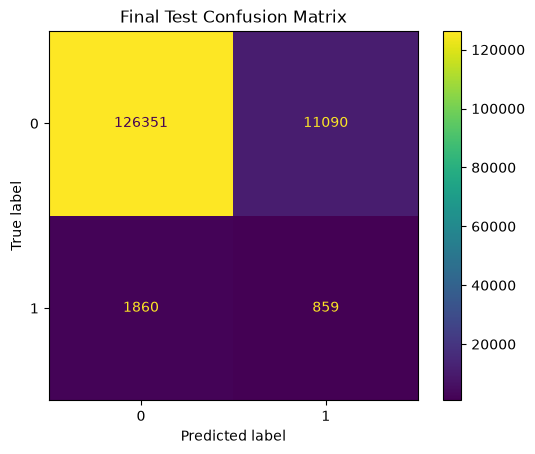

,feature,importance_mean,importance_std
4,days_since_last_hotspot,0.138405,0.000556
2,hotspot_prev_30d,0.087881,0.001417
3,avg_frp_prev_30d,0.013150,0.000695
1,hotspot_prev_14d,0.002736,0.000088
0,hotspot_prev_7d,0.002593,0.000056
5,peat_pct,0.000000,0.000000
6,month,-0.010766,0.000645
8,dry_season,-0.012728,0.000171
7,week_of_year,-0.015675,0.000916


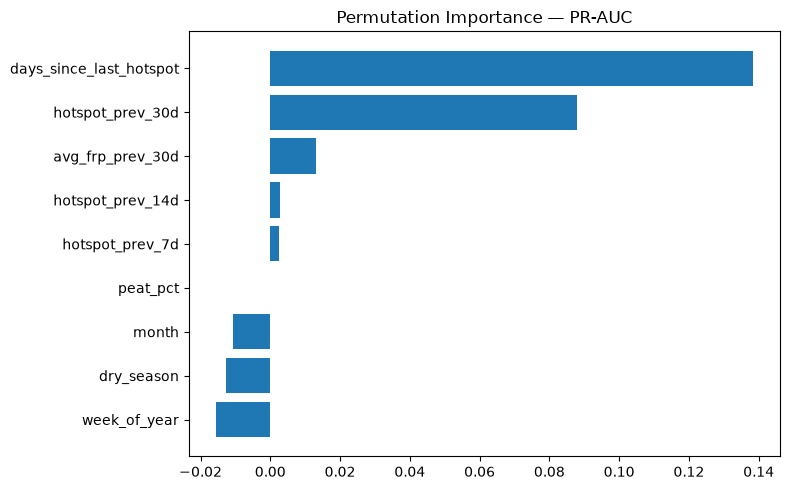

SHAP skipped: ModuleNotFoundError("No module named 'shap'")


In [22]:
BEST_CLASSIFIER_NAME=cls_results.iloc[0]['model']; BEST_CLASSIFIER_THRESHOLD=float(cls_results.iloc[0]['Threshold'])
train_final=model_df[model_df['week']<=MODEL_SELECTION_VAL_END].copy()
best_cls=clone(classification_models[BEST_CLASSIFIER_NAME]); best_cls.fit(train_final[FEATURES],train_final['fire_next_7d'])
test_prob=best_cls.predict_proba(test_final[FEATURES])[:,1]
final_cls_metrics=cls_metrics(test_final['fire_next_7d'],test_prob,BEST_CLASSIFIER_THRESHOLD)
display(pd.DataFrame([final_cls_metrics],index=[BEST_CLASSIFIER_NAME]))
ConfusionMatrixDisplay(confusion_matrix(test_final['fire_next_7d'],(test_prob>=BEST_CLASSIFIER_THRESHOLD).astype(int))).plot(); plt.title('Final Test Confusion Matrix'); plt.show()

perm=permutation_importance(best_cls,test_final[FEATURES],test_final['fire_next_7d'],scoring='average_precision',n_repeats=5,random_state=RANDOM_STATE,n_jobs=-1)
importance=pd.DataFrame({'feature':FEATURES,'importance_mean':perm.importances_mean,'importance_std':perm.importances_std}).sort_values('importance_mean',ascending=False)
display(importance)
top=importance.head(15).sort_values('importance_mean'); plt.figure(figsize=(8,5)); plt.barh(top['feature'],top['importance_mean']); plt.title('Permutation Importance — PR-AUC'); plt.tight_layout(); plt.show()

try:
    import shap
    if BEST_CLASSIFIER_NAME in ['Random Forest','XGBoost','LightGBM']:
        core=best_cls.named_steps['model']; imp=best_cls.named_steps['imputer']; samp=test_final[FEATURES].sample(min(3000,len(test_final)),random_state=RANDOM_STATE)
        Xs=pd.DataFrame(imp.transform(samp),columns=FEATURES); ex=shap.TreeExplainer(core); sv=ex(Xs); shap.summary_plot(sv,Xs,show=False); plt.tight_layout(); plt.show()
except Exception as e:
    print('SHAP skipped:',repr(e))

## 23. Count models — Poisson, NB, XGB-Poisson, LGBM-Poisson

In [23]:
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
import statsmodels.api as sm

count_train=train_sel['hotspot_count_next_7d']; dispersion=count_train.var()/max(count_train.mean(),1e-12)
print('Variance/mean:',dispersion)

count_models={
 'Poisson Regression':Pipeline([('imputer',SimpleImputer(strategy='median')),('scaler',StandardScaler()),('model',PoissonRegressor(alpha=.1,max_iter=1000))]),
 'XGBoost Poisson':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',XGBRegressor(objective='count:poisson',n_estimators=500,max_depth=6,learning_rate=.05,subsample=.8,colsample_bytree=.8,n_jobs=-1,random_state=RANDOM_STATE))]),
 'LightGBM Poisson':Pipeline([('imputer',SimpleImputer(strategy='median')),('model',LGBMRegressor(objective='poisson',n_estimators=500,learning_rate=.05,num_leaves=31,random_state=RANDOM_STATE,verbosity=-1))])
}

class NegativeBinomialWrapper:
    def __init__(self,alpha=None): self.alpha=alpha
    def fit(self,X,y):
        self.imputer=SimpleImputer(strategy='median'); self.scaler=StandardScaler(); Xi=self.imputer.fit_transform(X); Xs=sm.add_constant(self.scaler.fit_transform(Xi),has_constant='add')
        mu=np.mean(y); var=np.var(y,ddof=1); self.alpha_=self.alpha if self.alpha is not None else max((var-mu)/max(mu**2,1e-12),1e-6)
        self.result=sm.GLM(y,Xs,family=sm.families.NegativeBinomial(alpha=self.alpha_)).fit(maxiter=200); return self
    def predict(self,X):
        Xs=sm.add_constant(self.scaler.transform(self.imputer.transform(X)),has_constant='add'); return np.clip(np.asarray(self.result.predict(Xs)),1e-8,None)

def count_metrics(y,pred):
    pred=np.clip(np.asarray(pred,float),1e-8,None)
    return {'MAE':mean_absolute_error(y,pred),'RMSE':mean_squared_error(y,pred)**.5,'Poisson_Deviance':mean_poisson_deviance(y,pred)}

rows=[]; count_fitted={}
for name,m in count_models.items():
    print('Training',name); f=clone(m); f.fit(train_sel[FEATURES],train_sel['hotspot_count_next_7d']); pred=np.clip(f.predict(val_sel[FEATURES]),1e-8,None)
    rows.append({'model':name,**count_metrics(val_sel['hotspot_count_next_7d'],pred)}); count_fitted[name]=f
if dispersion>1:
    try:
        f=NegativeBinomialWrapper().fit(train_sel[FEATURES],train_sel['hotspot_count_next_7d']); pred=f.predict(val_sel[FEATURES]); rows.append({'model':'Negative Binomial',**count_metrics(val_sel['hotspot_count_next_7d'],pred)}); count_fitted['Negative Binomial']=f
    except Exception as e: print('NB failed:',repr(e))
count_results=pd.DataFrame(rows).sort_values(['MAE','Poisson_Deviance']).reset_index(drop=True); display(count_results)

Variance/mean: 11.40704971041934
Training Poisson Regression
Training XGBoost Poisson
Training LightGBM Poisson


,model,MAE,RMSE,Poisson_Deviance
0,LightGBM Poisson,2.372138e-01,1.273621e+00,7.181529e-01
1,XGBoost Poisson,2.401077e-01,1.204341e+00,7.194868e-01
2,Poisson Regression,2.424098e-01,5.430993e+00,9.507963e-01
3,Negative Binomial,9.315371e+36,4.591474e+39,1.863074e+37


## 24. Final count test

,MAE,RMSE,Poisson_Deviance
LightGBM Poisson,0.108241,0.937123,0.352006


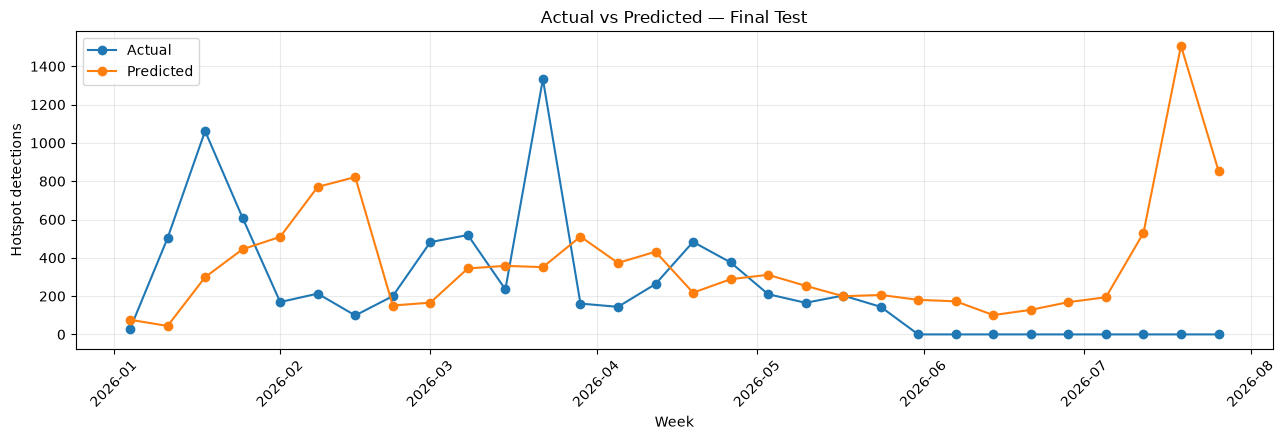

In [24]:
BEST_COUNT_NAME=count_results.iloc[0]['model']
if BEST_COUNT_NAME=='Negative Binomial': best_count=NegativeBinomialWrapper().fit(train_final[FEATURES],train_final['hotspot_count_next_7d'])
else:
    best_count=clone(count_models[BEST_COUNT_NAME]); best_count.fit(train_final[FEATURES],train_final['hotspot_count_next_7d'])
test_count_pred=np.clip(best_count.predict(test_final[FEATURES]),1e-8,None)
final_count_metrics=count_metrics(test_final['hotspot_count_next_7d'],test_count_pred)
display(pd.DataFrame([final_count_metrics],index=[BEST_COUNT_NAME]))

ct=test_final[['week','hotspot_count_next_7d']].copy(); ct['predicted']=test_count_pred
ct=ct.groupby('week').agg(actual=('hotspot_count_next_7d','sum'),predicted=('predicted','sum')).reset_index()
fig,ax=plt.subplots(figsize=(13,4.5)); ax.plot(ct['week'],ct['actual'],marker='o',label='Actual'); ax.plot(ct['week'],ct['predicted'],marker='o',label='Predicted')
ax.set(title='Actual vs Predicted — Final Test',xlabel='Week',ylabel='Hotspot detections'); ax.legend(); ax.grid(alpha=.25); plt.xticks(rotation=45); plt.tight_layout(); plt.show()

## 25. Data-driven risk & monitoring priority

priority_category
Low         77648
Watch       49760
Critical     9724
High         3028
Name: count, dtype: int64

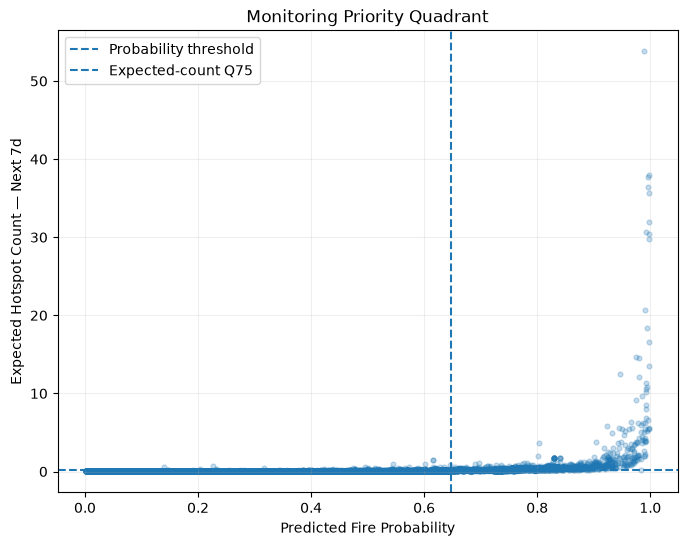

In [25]:
val_prob=cls_fitted[BEST_CLASSIFIER_NAME].predict_proba(val_sel[FEATURES])[:,1]
risk_q=np.maximum.accumulate(np.quantile(val_prob,[.50,.75,.90]))

def fire_risk_category(prob):
    q50,q75,q90=risk_q
    return np.select([prob<q50,(prob>=q50)&(prob<q75),(prob>=q75)&(prob<q90),prob>=q90],['Low','Moderate','High','Very High'],default='Low')

val_count_pred=np.clip(count_fitted[BEST_COUNT_NAME].predict(val_sel[FEATURES]),1e-8,None)
count_q50,count_q75=np.quantile(val_count_pred,[.50,.75])

def priority_category(prob,count_pred):
    high_prob=prob>=BEST_CLASSIFIER_THRESHOLD; high_count=count_pred>=count_q75
    watch_prob=prob>=risk_q[0]; watch_count=count_pred>=count_q50
    return np.select([high_prob&high_count,high_prob|high_count,watch_prob|watch_count],['Critical','High','Watch'],default='Low')

test_output=test_final[['grid_id','week','province','district','centroid_lat','centroid_lon','grid_area_km2']].copy()
if 'peat_pct' in test_final.columns: test_output['peat_pct']=test_final['peat_pct'].values
test_output['predicted_fire_probability']=test_prob
test_output['predicted_hotspot_count_next_7d']=test_count_pred
test_output['risk_category']=fire_risk_category(test_prob)
test_output['priority_category']=priority_category(test_prob,test_count_pred)
display(test_output['priority_category'].value_counts())

s=test_output.sample(min(len(test_output),30000),random_state=RANDOM_STATE)
fig,ax=plt.subplots(figsize=(8,6)); ax.scatter(s['predicted_fire_probability'],s['predicted_hotspot_count_next_7d'],alpha=.25,s=12)
ax.axvline(BEST_CLASSIFIER_THRESHOLD,ls='--',label='Probability threshold'); ax.axhline(count_q75,ls='--',label='Expected-count Q75')
ax.set(title='Monitoring Priority Quadrant',xlabel='Predicted Fire Probability',ylabel='Expected Hotspot Count — Next 7d'); ax.legend(); ax.grid(alpha=.2); plt.show()

## 26. Top priority areas

In [29]:
latest_week=test_output['week'].max(); latest=test_output[test_output['week']==latest_week].copy()
rank={'Critical':3,'High':2,'Watch':1,'Low':0}; latest['_rank']=latest['priority_category'].map(rank)
top_priority=(latest.sort_values(['_rank','predicted_fire_probability','predicted_hotspot_count_next_7d'],ascending=False).drop(columns='_rank').head(10))
print('Latest prediction origin:',latest_week.date()); display(top_priority)

Latest prediction origin: 2026-07-26


,grid_id,week,province,district,centroid_lat,centroid_lon,grid_area_km2,peat_pct,predicted_fire_probability,predicted_hotspot_count_next_7d,risk_category,priority_category
2158,G00016,2026-07-26,South Kalimantan,Tanah Laut,-4.047923,114.669134,81.705357,NaN,0.859724,0.479082,Very High,Critical
5533,G00041,2026-07-26,South Kalimantan,Tanah Laut,-3.845459,115.250000,121.574148,NaN,0.859724,0.479082,Very High,Critical
19168,G00142,2026-07-26,South Kalimantan,Kota Baru,-3.448977,116.373247,63.573752,NaN,0.859724,0.479082,Very High,Critical
42928,G00318,2026-07-26,South Kalimantan,Kota Baru,-3.049999,115.650000,122.921005,NaN,0.859724,0.479082,Very High,Critical
111778,G00828,2026-07-26,South Kalimantan,Tabalong,-2.249999,115.450000,122.998345,NaN,0.859724,0.479082,Very High,Critical
208573,G01545,2026-07-26,Central Kalimantan,Katingan,-1.150000,112.650000,123.066576,NaN,0.859724,0.479082,Very High,Critical
220318,G01632,2026-07-26,Central Kalimantan,Gunung Mas,-1.050000,113.650000,123.070590,NaN,0.859724,0.479082,Very High,Critical
270538,G02004,2026-07-26,West Kalimantan,Kubu Raya,-0.541783,109.350000,111.708531,NaN,0.859724,0.479082,Very High,Critical
339658,G02516,2026-07-26,West Kalimantan,Mempawah,0.050000,109.350000,123.090660,NaN,0.859724,0.479082,Very High,Critical
351268,G02602,2026-07-26,West Kalimantan,Mempawah,0.150000,109.250000,123.090295,NaN,0.859724,0.479082,Very High,Critical


## 27. Export dashboard-ready tables & models

In [30]:
fact_cols=['grid_id','week','centroid_lat','centroid_lon','province','district','grid_area_km2','hotspot_count','avg_frp','max_frp','high_confidence_rate',
           'hotspot_prev_7d','hotspot_prev_14d','hotspot_prev_30d','avg_frp_prev_30d','days_since_last_hotspot','peat_pct',
           'rainfall_7d','rainfall_14d','rainfall_30d','temperature_mean_7d','temperature_max_7d','soil_moisture_7d','dry_days_30d','month','week_of_year','dry_season']
fact_cols=[c for c in fact_cols if c in model_df.columns]
fact_grid_week=model_df[fact_cols].copy(); prediction_grid_week=test_output.copy()
dim_grid=grid[['grid_id','centroid_lat','centroid_lon','province','district','grid_area_km2','geometry']].copy()
dim_date=pd.DataFrame({'date':pd.date_range(START_DATE,END_DATE,freq='D')}); dim_date['week']=week_end_sunday(dim_date['date']); dim_date['month']=dim_date['date'].dt.month; dim_date['year']=dim_date['date'].dt.year; dim_date['week_of_year']=dim_date['date'].dt.isocalendar().week.astype(int)

final_metrics=pd.DataFrame([
 {'task':'classification','model':BEST_CLASSIFIER_NAME,'stage':'final_test_2026',**final_cls_metrics},
 {'task':'count_prediction','model':BEST_COUNT_NAME,'stage':'final_test_2026',**final_count_metrics},
])

fact_grid_week.to_parquet(PROCESSED_DIR/'fact_grid_week.parquet',index=False)
prediction_grid_week.to_parquet(PROCESSED_DIR/'prediction_grid_week.parquet',index=False)
safe_save_gdf(dim_grid,PROCESSED_DIR/'dim_grid.geojson')
dim_date.to_parquet(PROCESSED_DIR/'dim_date.parquet',index=False)
cls_results.to_csv(PROCESSED_DIR/'classification_validation_metrics.csv',index=False)
count_results.to_csv(PROCESSED_DIR/'count_validation_metrics.csv',index=False)
final_metrics.to_csv(PROCESSED_DIR/'final_test_metrics.csv',index=False)
top_priority.to_csv(PROCESSED_DIR/'top10_priority_areas.csv',index=False)

joblib.dump({'model':best_cls,'features':FEATURES,'threshold':BEST_CLASSIFIER_THRESHOLD,'name':BEST_CLASSIFIER_NAME,'risk_quantiles':risk_q},MODEL_DIR/'best_fire_occurrence_classifier.joblib')
joblib.dump({'model':best_count,'features':FEATURES,'name':BEST_COUNT_NAME,'count_q50':count_q50,'count_q75':count_q75},MODEL_DIR/'best_hotspot_count_model.joblib')
print('Exports complete.'); [print('-', p.name) for p in sorted(PROCESSED_DIR.glob('*'))]

Exports complete.
- classification_validation_metrics.csv
- count_validation_metrics.csv
- dim_date.parquet
- dim_grid.geojson
- fact_grid_week.parquet
- final_test_metrics.csv
- prediction_grid_week.parquet
- top10_priority_areas.csv


[None, None, None, None, None, None, None, None]

## 28. Methodological sanity checks

In [31]:
assert not fact_grid_week.duplicated(['grid_id','week']).any()
assert (model_df['hotspot_count_next_7d']>=0).all()
assert np.all((test_prob>=0)&(test_prob<=1))
assert np.all(test_count_pred>=0)
assert train_sel['week'].max()<val_sel['week'].min()<test_final['week'].min()
assert 'fire_next_7d' not in FEATURES and 'hotspot_count_next_7d' not in FEATURES
print('✅ Core checks passed.')

✅ Core checks passed.


## 29. Business-question mapping

### BQ1 — Historical
**Where and when has fire activity historically concentrated in Kalimantan?**
- monthly trend
- year × month seasonality
- district/grid density

### BQ2 — Environmental
**How do environmental conditions differ across areas with different levels of fire activity?**
- rainfall vs hotspot
- soil moisture vs hotspot
- peat vs non-peat
- optional land-cover composition

Interpretation harus memakai **associated with**, bukan langsung **causes**.

### BQ3 — Fire Risk
**Which areas are most likely to experience hotspot activity during the next seven days?**
- `predicted_fire_probability`
- PR-AUC / ROC-AUC / Recall / F1
- importance / SHAP

### BQ4 — Expected Count
**Which areas are expected to experience the highest hotspot activity during the next seven days?**
- `predicted_hotspot_count_next_7d`
- MAE / RMSE / Poisson deviance
- actual vs predicted

### BQ5 — Monitoring Priority
**Which areas should receive the highest monitoring priority?**
- probability × expected-count quadrant
- `priority_category`
- top-priority area table

## 30. Final output structure

```text
kalimantan_firewatch/
├── data/
│   ├── raw/
│   │   ├── firms/
│   │   ├── boundaries/
│   │   ├── era5_land/
│   │   ├── peatland/
│   │   ├── mapbiomas/
│   │   └── mapbiomas_fire/
│   ├── interim/
│   │   ├── firms_kalimantan_clean.parquet
│   │   ├── fire_history_features.parquet
│   │   ├── era5_daily.parquet
│   │   └── era5_grid_week.parquet
│   └── processed/
│       ├── fact_grid_week.parquet
│       ├── prediction_grid_week.parquet
│       ├── dim_grid.geojson
│       ├── dim_date.parquet
│       ├── classification_validation_metrics.csv
│       ├── count_validation_metrics.csv
│       ├── final_test_metrics.csv
│       └── top10_priority_areas.csv
└── models/
    ├── best_fire_occurrence_classifier.joblib
    └── best_hotspot_count_model.joblib
```

**Dashboard sengaja belum dibuat.** Tiga input utama untuk tahap dashboard nanti:
- `dim_grid.geojson`
- `fact_grid_week.parquet`
- `prediction_grid_week.parquet`